<a href="https://colab.research.google.com/github/Handinoasa/MachineLearning_2026/blob/main/MLWeek11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS13 ANN dan Evaluasi Classifier

- Nama: Handino Asa Galih R
- Kelas: TI 3E
- Nim: 244107020237

# Praktikum 1

In [ ]:
import numpy as np

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# Parameter
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Inisialisasi bobot
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Fungsi aktivasi
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# Training
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        loss = np.mean(np.square(error))
        print(f"Epoch {epoch}, Loss: {loss}")

# Output akhir
print("Prediksi:")
print(a2)

Epoch 0, Loss: 0.2537911016570847
Epoch 1000, Loss: 0.2501514067627669
Epoch 2000, Loss: 0.24986681859561286
Epoch 3000, Loss: 0.24950616085232025
Epoch 4000, Loss: 0.24784000150853094
Epoch 5000, Loss: 0.23319441438132746
Epoch 6000, Loss: 0.15482682644059367
Epoch 7000, Loss: 0.029710860599143463
Epoch 8000, Loss: 0.01172965792668052
Epoch 9000, Loss: 0.006888867073073044
Prediksi:
[[0.07004516]
 [0.93232764]
 [0.92376991]
 [0.06179342]]


Tugas - 1

- Ubah jumlah neuron hidden layer menjadi 3.

- Bandingkan hasil loss dengan konfigurasi awa-l.

- Tambahkan fungsi aktivasi ReLU dan bandingkan hasil.

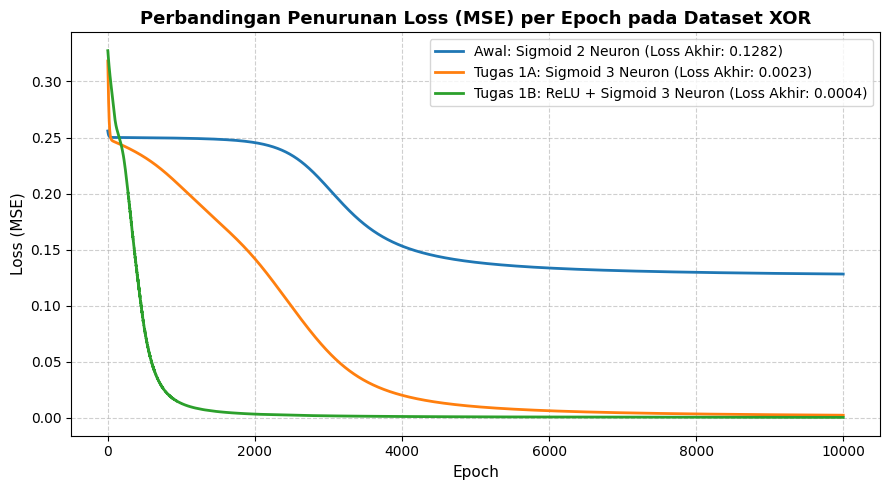

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Dataset XOR
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

def latih_xor(hidden_size, gunakan_relu=False, epochs=10000, lr=0.1, seed=42):
    np.random.seed(seed)
    W1 = np.random.randn(2, hidden_size)
    b1 = np.zeros((1, hidden_size))
    W2 = np.random.randn(hidden_size, 1)
    b2 = np.zeros((1, 1))
    riwayat_loss = []

    for epoch in range(epochs):
        # Forward pass
        z1 = np.dot(X, W1) + b1
        a1 = relu(z1) if gunakan_relu else sigmoid(z1)
        z2 = np.dot(a1, W2) + b2
        a2 = sigmoid(z2)

        # Hitung error dan simpan loss
        error = y - a2
        riwayat_loss.append(np.mean(np.square(error)))

        # Backpropagation
        d_a2 = error * sigmoid_derivative(a2)
        d_W2 = np.dot(a1.T, d_a2)
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        if gunakan_relu:
            d_a1 = np.dot(d_a2, W2.T) * relu_derivative(z1)
        else:
            d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)

        d_W1 = np.dot(X.T, d_a1)
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        # Update bobot
        W1 += lr * d_W1
        b1 += lr * d_b1
        W2 += lr * d_W2
        b2 += lr * d_b2

    return riwayat_loss, a2

# Jalankan ketiga skenario
loss_awal, pred_awal = latih_xor(hidden_size=2, gunakan_relu=False)
loss_t1a, pred_t1a   = latih_xor(hidden_size=3, gunakan_relu=False)
loss_t1b, pred_t1b   = latih_xor(hidden_size=3, gunakan_relu=True)

# Visualisasi Grafik Garis Loss XOR
plt.figure(figsize=(9, 5))
plt.plot(loss_awal, label=f'Awal: Sigmoid 2 Neuron (Loss Akhir: {loss_awal[-1]:.4f})', linewidth=2)
plt.plot(loss_t1a,  label=f'Tugas 1A: Sigmoid 3 Neuron (Loss Akhir: {loss_t1a[-1]:.4f})', linewidth=2)
plt.plot(loss_t1b,  label=f'Tugas 1B: ReLU + Sigmoid 3 Neuron (Loss Akhir: {loss_t1b[-1]:.4f})', linewidth=2)

plt.title('Perbandingan Penurunan Loss (MSE) per Epoch pada Dataset XOR', fontsize=13, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss (MSE)', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Berdasarkan hasil pengujian ketiga konfigurasi di atas, berikut adalah analisis perbandingannya:

Penambahan neuron (hidden_size = 2 ke 3 pada Sigmoid): Menurunkan loss akhir secara drastis dari 0,128227 menjadi 0,002297 karena tambahan ruang representasi membebaskan jaringan dari local minimum dan membuat seluruh pola XOR terprediksi akurat.

Penggunaan ReLU pada hidden layer (hidden_size = 3): Menghasilkan loss akhir terendah sebesar 0,000352 dengan nilai prediksi paling tajam mendekati target (0 dan 1) dibandingkan aktivasi Sigmoid murni.

Kecepatan konvergensi (ReLU vs. Sigmoid): Mempercepat penurunan loss sejak awal pelatihan (mencapai 0,012797 pada Epoch 1.000) karena ReLU memiliki turunan konstan bernilai 1 untuk nilai positif sehingga bebas dari penyusutan gradien (vanishing gradient) pada Sigmoid yang turunannya maksimal 0,25.

Kombinasi aktivasi lapisan keluaran: Mempertahankan Sigmoid pada output layer untuk menjaga prediksi dalam rentang probabilitas 0 hingga 1 sekaligus mencegah masalah Dying ReLU (bobot berhenti diperbarui saat nilai pra-aktivasi bernilai negatif atau nol).

# Praktikum 2

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf
import numpy as np

# Set random seed agar perbandingan hasil konsisten
np.random.seed(5)
tf.random.set_seed(5)

# 1 & 2. Load dataset dan One-hot encoding
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# Catatan: gunakan sparse_output=False pada scikit-learn >= 1.2 (atau sparse=False pada versi lama)
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

# 3. Bangun model (Konfigurasi Awal: 10 -> 8 -> 3, ReLU)
model_awal = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# 4. Kompilasi dan latih model
model_awal.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_awal.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)

# 5. Evaluasi hasil
loss_awal, acc_awal = model_awal.evaluate(X_test, y_test, verbose=0)
print(f"Konfigurasi Awal (10-8, ReLU) -> Loss: {loss_awal:.4f}, Akurasi: {acc_awal:.4f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Konfigurasi Awal (10-8, ReLU) -> Loss: 1.1156, Akurasi: 0.2000


# Tugas 2 dan 3

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4-4 ReLU (Tugas 2A)      -> Test Loss: 0.7672 | Test Akurasi: 76.67%
10-8 ReLU (Awal)         -> Test Loss: 0.4382 | Test Akurasi: 63.33%
32-16 ReLU (Tugas 2B)    -> Test Loss: 0.2174 | Test Akurasi: 100.00%
10-8 Sigmoid (Tugas 3)   -> Test Loss: 0.7514 | Test Akurasi: 56.67%


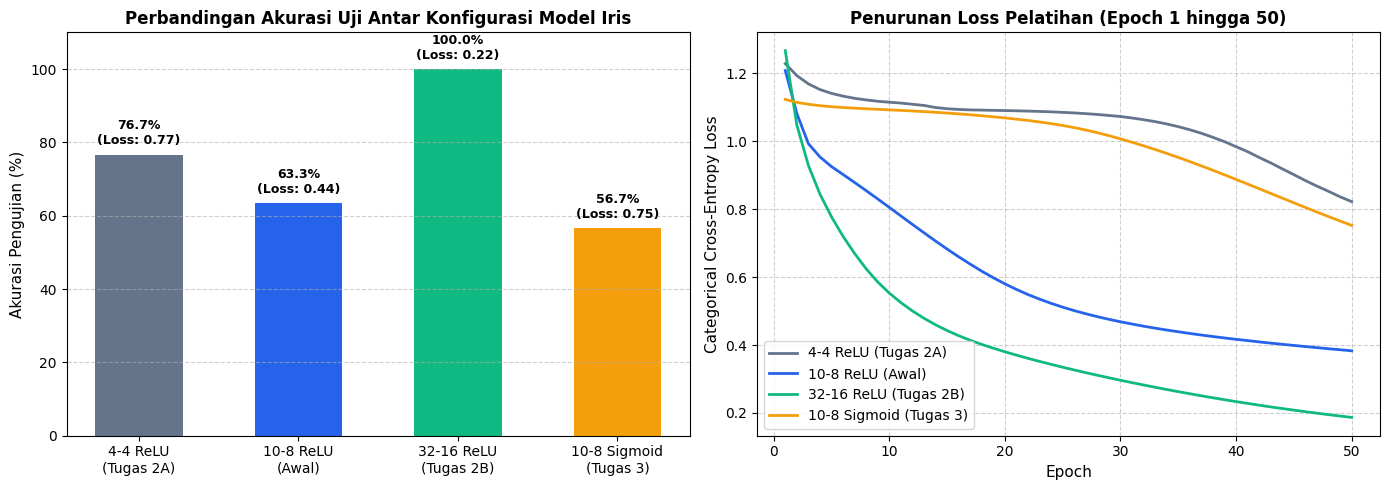

In [5]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# 1. Persiapan Data Iris
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

# Fungsi pembantu untuk membangun, melatih, dan mengevaluasi model
def bangun_dan_latih(h1, h2, aktivasi, seed=5):
    np.random.seed(seed)
    tf.random.set_seed(seed)
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(h1, activation=aktivasi, input_shape=(4,)),
        tf.keras.layers.Dense(h2, activation=aktivasi),
        tf.keras.layers.Dense(3, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    history = model.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    return history.history['loss'], test_loss, test_acc * 100

# 2. Jalankan keempat konfigurasi (Praktikum 2, Tugas 2, dan Tugas 3)
skenario = [
    ("4-4 ReLU\n(Tugas 2A)",   4,  4,  'relu'),
    ("10-8 ReLU\n(Awal)",      10, 8,  'relu'),
    ("32-16 ReLU\n(Tugas 2B)", 32, 16, 'relu'),
    ("10-8 Sigmoid\n(Tugas 3)", 10, 8, 'sigmoid')
]

riwayat_loss_dict = {}
label_model = []
akurasi_uji = []
loss_uji = []

for nama, h1, h2, akt in skenario:
    hist_loss, t_loss, t_acc = bangun_dan_latih(h1, h2, akt)
    nama_satu_baris = nama.replace('\n', ' ')
    riwayat_loss_dict[nama_satu_baris] = hist_loss
    label_model.append(nama)
    loss_uji.append(t_loss)
    akurasi_uji.append(t_acc)
    print(f"{nama_satu_baris:24s} -> Test Loss: {t_loss:.4f} | Test Akurasi: {t_acc:.2f}%")

# 3. Buat Visualisasi Berdampingan (Bar Chart Akurasi & Line Chart Loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Grafik Batang Perbandingan Akurasi Pengujian (%)
warna_bar = ['#64748b', '#2563eb', '#10b981', '#f59e0b']
bars = ax1.bar(label_model, akurasi_uji, color=warna_bar, width=0.55)
ax1.set_title('Perbandingan Akurasi Uji Antar Konfigurasi Model Iris', fontsize=12, fontweight='bold')
ax1.set_ylabel('Akurasi Pengujian (%)', fontsize=11)
ax1.set_ylim(0, 110)
ax1.grid(axis='y', linestyle='--', alpha=0.6)

# Tambahkan label angka persentase dan test loss di atas setiap batang
for bar, acc_val, l_val in zip(bars, akurasi_uji, loss_uji):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{acc_val:.1f}%\n(Loss: {l_val:.2f})",
        ha='center', va='bottom', fontsize=9, fontweight='bold'
    )

# Subplot 2: Grafik Garis Penurunan Loss Pelatihan per Epoch
epochs_range = range(1, 51)
for (nama_seri, kurva_loss), warna in zip(riwayat_loss_dict.items(), warna_bar):
    ax2.plot(epochs_range, kurva_loss, label=nama_seri, color=warna, linewidth=2)

ax2.set_title('Penurunan Loss Pelatihan (Epoch 1 hingga 50)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch', fontsize=11)
ax2.set_ylabel('Categorical Cross-Entropy Loss', fontsize=11)
ax2.legend(fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Praktikum 3 Tugas 4

LR: 0.0005 | Train MSE Akhir: 1.225161 | Test MSE: 0.564592 | Prediksi: 706.26 (Target: 600)


LR: 0.001  | Train MSE Akhir: 0.124801 | Test MSE: 0.020162 | Prediksi: 620.08 (Target: 600)
LR: 0.01   | Train MSE Akhir: 0.006047 | Test MSE: 0.064025 | Prediksi: 564.22 (Target: 600)
LR: 0.05   | Train MSE Akhir: 0.000004 | Test MSE: 0.012681 | Prediksi: 584.07 (Target: 600)


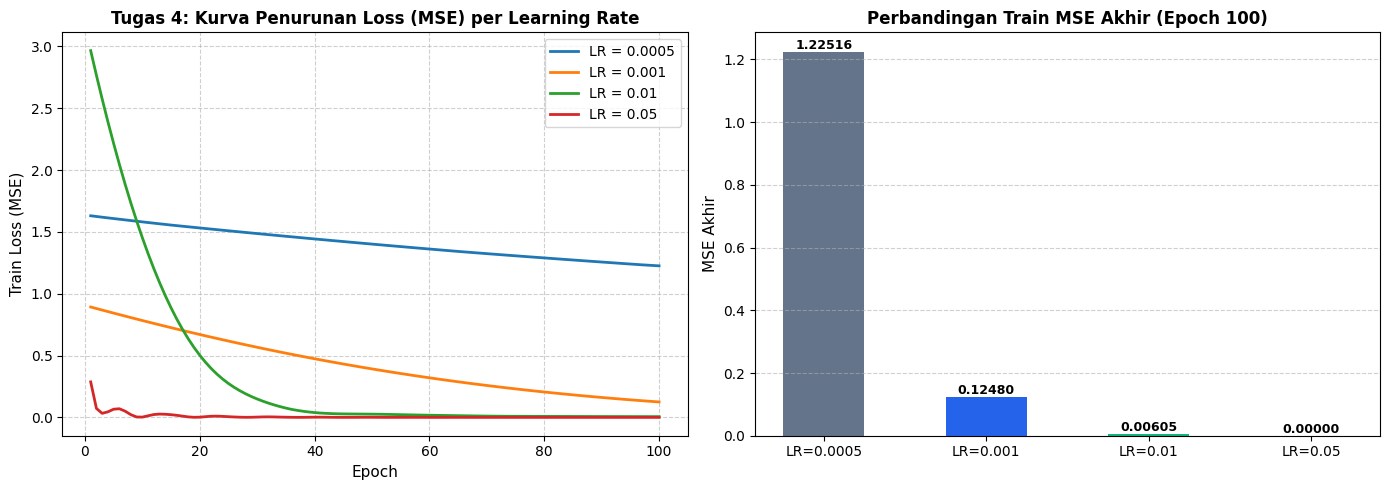

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# 1. Buat dummy data luas dan harga rumah
data = pd.DataFrame({
    'luas': [50.0, 60.0, 70.0, 80.0, 90.0],
    'harga': [500.0, 600.0, 700.0, 800.0, 900.0]
})

# Gunakan 2 scaler terpisah agar prediksi dapat dikembalikan ke satuan harga asli
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X = scaler_X.fit_transform(data[['luas']])
y = scaler_y.fit_transform(data[['harga']])

# Split data dengan random_state tetap agar perbandingan adil
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Eksperimen Tugas 4: Variasi Learning Rate
daftar_lr = [0.0005, 0.001, 0.01, 0.05]
riwayat_loss_lr = {}
hasil_evaluasi = []

for lr in daftar_lr:
    np.random.seed(42)
    tf.random.set_seed(42)

    model = tf.keras.Sequential([
        tf.keras.Input(shape=(1,)),
        tf.keras.layers.Dense(10, activation='relu'),
        tf.keras.layers.Dense(1)
    ])

    optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
    model.compile(optimizer=optimizer, loss='mse')
    history = model.fit(X_train, y_train, epochs=100, verbose=0)

    riwayat_loss_lr[f"LR = {lr}"] = history.history['loss']
    test_mse = model.evaluate(X_test, y_test, verbose=0)
    pred_norm = model.predict(X_test, verbose=0)
    pred_asli = scaler_y.inverse_transform(pred_norm)[0, 0]
    target_asli = scaler_y.inverse_transform(y_test)[0, 0]

    hasil_evaluasi.append((lr, history.history['loss'][-1], test_mse, pred_asli))
    print(f"LR: {lr:<6} | Train MSE Akhir: {history.history['loss'][-1]:.6f} | "
          f"Test MSE: {test_mse:.6f} | Prediksi: {pred_asli:.2f} (Target: {target_asli:.0f})")

# 3. Visualisasi Kurva Loss & Bar Chart MSE Akhir untuk Google Colab
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for label_lr, kurva in riwayat_loss_lr.items():
    ax1.plot(range(1, 101), kurva, label=label_lr, linewidth=2)

ax1.set_title('Tugas 4: Kurva Penurunan Loss (MSE) per Learning Rate', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch', fontsize=11)
ax1.set_ylabel('Train Loss (MSE)', fontsize=11)
ax1.legend(fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)

label_bar = [f"LR={r[0]}" for r in hasil_evaluasi]
nilai_mse = [r[1] for r in hasil_evaluasi]
warna = ['#64748b', '#2563eb', '#10b981', '#f59e0b']
bars = ax2.bar(label_bar, nilai_mse, color=warna, width=0.5)
ax2.set_title('Perbandingan Train MSE Akhir (Epoch 100)', fontsize=12, fontweight='bold')
ax2.set_ylabel('MSE Akhir', fontsize=11)
ax2.grid(axis='y', linestyle='--', alpha=0.6)

for bar, val in zip(bars, nilai_mse):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f"{val:.5f}", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

# Tugas Praktikum

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
=== Memulai Eksperimen Pelatihan MNIST (10 Epoch per Model) ===


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1. Baseline (128-64, ReLU)             -> Akurasi Uji: 97.16% | Loss Uji: 0.1021 | Waktu: 38.40 detik
2. Ubah Neuron (256-128, ReLU)         -> Akurasi Uji: 97.52% | Loss Uji: 0.1020 | Waktu: 39.64 detik
3. +1 Hidden Layer (256-128-64, ReLU)  -> Akurasi Uji: 97.65% | Loss Uji: 0.0931 | Waktu: 41.29 detik
4. Aktivasi Sigmoid (256-128, Sigmoid) -> Akurasi Uji: 97.43% | Loss Uji: 0.0810 | Waktu: 39.17 detik


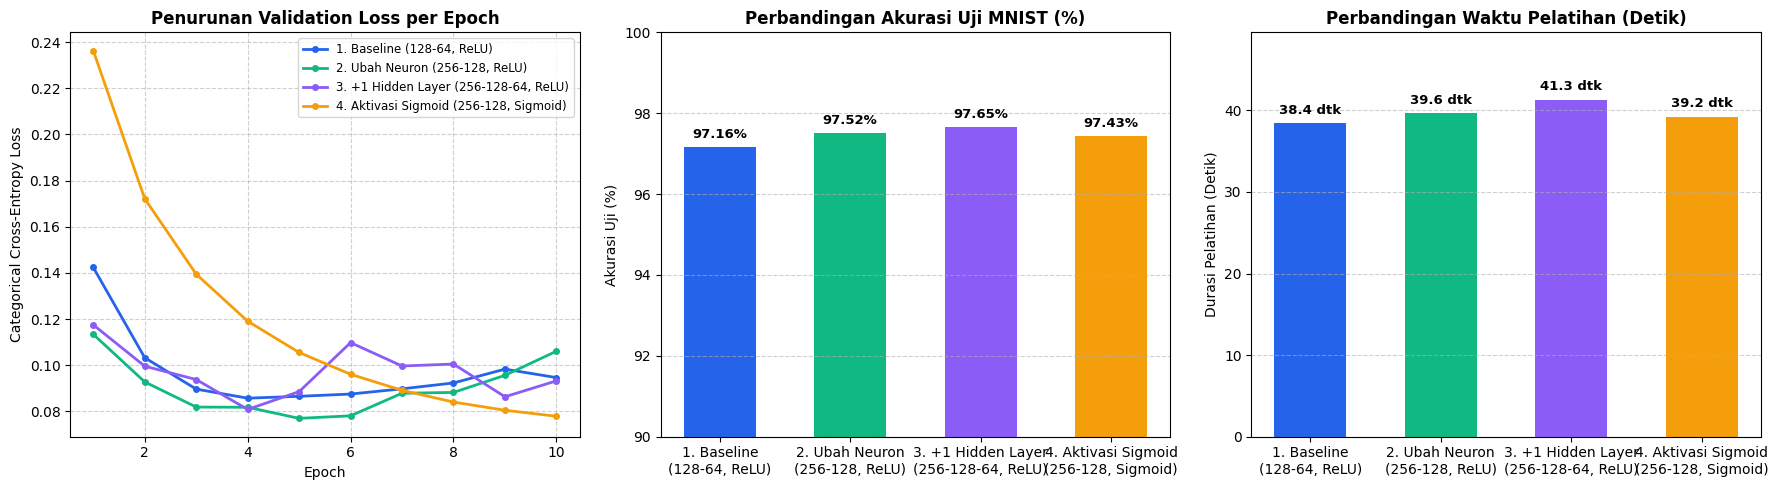

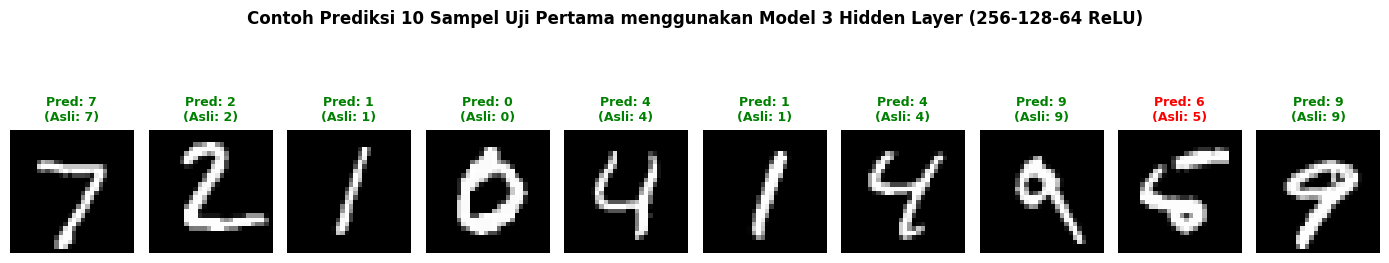

In [8]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

# 1. Load & Preprocess Data MNIST
(X_train, y_train_raw), (X_test, y_test_raw) = mnist.load_data()
X_train = X_train / 255.0
X_test = X_test / 255.0
y_train = to_categorical(y_train_raw, 10)
y_test = to_categorical(y_test_raw, 10)

# 2. Definisi 4 Skenario Eksperimen Tugas Praktikum
konfigurasi_mnist = [
    {
        "nama": "1. Baseline\n(128-64, ReLU)",
        "layers": [128, 64],
        "aktivasi": "relu"
    },
    {
        "nama": "2. Ubah Neuron\n(256-128, ReLU)",
        "layers": [256, 128],
        "aktivasi": "relu"
    },
    {
        "nama": "3. +1 Hidden Layer\n(256-128-64, ReLU)",
        "layers": [256, 128, 64],
        "aktivasi": "relu"
    },
    {
        "nama": "4. Aktivasi Sigmoid\n(256-128, Sigmoid)",
        "layers": [256, 128],
        "aktivasi": "sigmoid"
    }
]

riwayat_val_acc = {}
riwayat_val_loss = {}
ringkasan_hasil = []
model_terbaik = None

print("=== Memulai Eksperimen Pelatihan MNIST (10 Epoch per Model) ===")
for cfg in konfigurasi_mnist:
    np.random.seed(42)
    tf.random.set_seed(42)

    # Susun layer secara dinamis sesuai konfigurasi
    daftar_layer = [Flatten(input_shape=(28, 28))]
    for jml_neuron in cfg["layers"]:
        daftar_layer.append(Dense(jml_neuron, activation=cfg["aktivasi"]))
    daftar_layer.append(Dense(10, activation='softmax'))

    model_exp = Sequential(daftar_layer)
    model_exp.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    # Catat waktu mulai pelatihan
    waktu_mulai = time.perf_counter()
    hist = model_exp.fit(
        X_train, y_train,
        epochs=10,
        batch_size=128,
        validation_split=0.1,
        verbose=0
    )
    durasi_latih = time.perf_counter() - waktu_mulai

    # Evaluasi pada data uji (10.000 gambar)
    test_loss, test_acc = model_exp.evaluate(X_test, y_test, verbose=0)
    nama_bersih = cfg["nama"].replace("\n", " ")

    riwayat_val_acc[nama_bersih] = [a * 100 for a in hist.history['val_accuracy']]
    riwayat_val_loss[nama_bersih] = hist.history['val_loss']
    ringkasan_hasil.append({
        "label": cfg["nama"],
        "nama_bersih": nama_bersih,
        "test_acc": test_acc * 100,
        "test_loss": test_loss,
        "waktu": durasi_latih
    })

    if cfg["layers"] == [256, 128, 64]:
        model_terbaik = model_exp

    print(f"{nama_bersih:38s} -> Akurasi Uji: {test_acc*100:.2f}% | "
          f"Loss Uji: {test_loss:.4f} | Waktu: {durasi_latih:.2f} detik")

# 3. Visualisasi Panel 1: Kurva Val Loss, Bar Chart Akurasi, dan Bar Chart Waktu Pelatihan
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))
warna_palet = ['#2563eb', '#10b981', '#8b5cf6', '#f59e0b']

# Panel A: Grafik Garis Validation Loss per Epoch
epochs_x = range(1, 11)
for (nama_m, kurva_l), warna in zip(riwayat_val_loss.items(), warna_palet):
    ax1.plot(epochs_x, kurva_l, marker='o', markersize=4, label=nama_m, color=warna, linewidth=2)
ax1.set_title('Penurunan Validation Loss per Epoch', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Categorical Cross-Entropy Loss')
ax1.legend(fontsize=8.5)
ax1.grid(True, linestyle='--', alpha=0.6)

# Panel B: Grafik Batang Akurasi Data Uji (%)
label_x = [r["label"] for r in ringkasan_hasil]
nilai_acc = [r["test_acc"] for r in ringkasan_hasil]
bars_acc = ax2.bar(label_x, nilai_acc, color=warna_palet, width=0.55)
ax2.set_title('Perbandingan Akurasi Uji MNIST (%)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Akurasi Uji (%)')
ax2.set_ylim(90, 100)
ax2.grid(axis='y', linestyle='--', alpha=0.6)
for bar, val in zip(bars_acc, nilai_acc):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.15,
             f"{val:.2f}%", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# Panel C: Grafik Batang Waktu Pelatihan (Detik)
nilai_waktu = [r["waktu"] for r in ringkasan_hasil]
bars_waktu = ax3.bar(label_x, nilai_waktu, color=warna_palet, width=0.55)
ax3.set_title('Perbandingan Waktu Pelatihan (Detik)', fontsize=12, fontweight='bold')
ax3.set_ylabel('Durasi Pelatihan (Detik)')
ax3.set_ylim(0, max(nilai_waktu) * 1.2)
ax3.grid(axis='y', linestyle='--', alpha=0.6)
for bar, val in zip(bars_waktu, nilai_waktu):
    ax3.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + (max(nilai_waktu) * 0.02),
             f"{val:.1f} dtk", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

# 4. Visualisasi Panel 2: Contoh 10 Citra Uji MNIST beserta Hasil Prediksi Model
pred_prob = model_terbaik.predict(X_test[:10], verbose=0)
pred_kelas = np.argmax(pred_prob, axis=1)

plt.figure(figsize=(14, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_test[i], cmap='gray')
    warna_teks = 'green' if pred_kelas[i] == y_test_raw[i] else 'red'
    plt.title(f"Pred: {pred_kelas[i]}\n(Asli: {y_test_raw[i]})", color=warna_teks, fontsize=9, fontweight='bold')
    plt.axis('off')
plt.suptitle('Contoh Prediksi 10 Sampel Uji Pertama menggunakan Model 3 Hidden Layer (256-128-64 ReLU)',
             fontsize=12, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()